# 03 — Linear regression as Gaussian maximum likelihood: predicting the expected_score

**Phase 1, Step 5.** Target: the **expected_score** (0–100) for each
requirement–vendor pair, in the `expected_score` column of
`data/annotation/annotation_sheet.csv`.

> **What the target is.** A person read each pair's vendor title, address and listed categories and scored it against
> `data/annotation/RUBRIC.md`, one requirement (15 pairs) at a time, with a short rationale
> per pair (`data/annotation/ai_scores.csv`). Every result below describes how well a linear model
> reproduces the scores

Features (per pair): `distance_km`, `within_radius`, `category_match`, `keyword_in_title`,
`n_categories`, `is_chain`, plus an intercept.

## 1. The model

$$y = X\beta + \varepsilon, \qquad \varepsilon \sim N(0, \sigma^2 I_n)$$

$y \in \mathbb{R}^n$ are the scores, $X \in \mathbb{R}^{n \times p}$ the design matrix
(column of ones + 6 features, so $p = 7$), $\beta \in \mathbb{R}^p$ the coefficients.
Equivalently, $y_i \mid x_i \sim N(x_i^\top\beta, \sigma^2)$ independently.

## 2. Likelihood and log-likelihood

$$L(\beta, \sigma^2) = \prod_{i=1}^{n} \frac{1}{\sqrt{2\pi\sigma^2}}
\exp\!\Big(-\frac{(y_i - x_i^\top\beta)^2}{2\sigma^2}\Big)$$

$$\ell(\beta, \sigma^2) = -\frac{n}{2}\log(2\pi\sigma^2)
- \frac{1}{2\sigma^2}\sum_{i=1}^{n}(y_i - x_i^\top\beta)^2
= -\frac{n}{2}\log(2\pi\sigma^2) - \frac{\mathrm{RSS}(\beta)}{2\sigma^2}.$$

## 3. Maximising over $\beta$ is minimising RSS

For any fixed $\sigma^2 > 0$, the first term does not involve $\beta$ and the second is
$-\mathrm{RSS}(\beta)$ times a positive constant $1/(2\sigma^2)$. So

$$\arg\max_\beta \ell(\beta, \sigma^2) = \arg\min_\beta \mathrm{RSS}(\beta)
= \arg\min_\beta \lVert y - X\beta\rVert^2 .$$

The Gaussian MLE of $\beta$ **is** the least-squares estimate. (This equivalence rests on
the Gaussian error assumption; with other error distributions the MLE is a different
estimator.)

## 4. The closed form

$\nabla_\beta \mathrm{RSS} = -2X^\top(y - X\beta) = 0$ gives the normal equations
$X^\top X\,\beta = X^\top y$. If $X$ has full column rank, $X^\top X$ is invertible and

$$\hat\beta = (X^\top X)^{-1} X^\top y .$$

Unlike logistic regression (notebook 02), the score equations are linear in $\beta$, so a
closed form exists. **In code** we solve with `numpy.linalg.lstsq` (orthogonal
decomposition), not the explicit inverse: forming $X^\top X$ squares the condition number,
$\kappa(X^\top X) = \kappa(X)^2$, which loses accuracy when features are nearly collinear.
The explicit inverse is computed only as a small cross-check, and scikit-learn's
`LinearRegression` as a second check. We also print $\kappa(X)$.

## 5. Estimating $\sigma^2$

Plug in $\hat\beta$ and differentiate with respect to $\sigma^2$:

$$\frac{\partial \ell}{\partial \sigma^2} = -\frac{n}{2\sigma^2} + \frac{\mathrm{RSS}}{2\sigma^4} = 0
\;\Rightarrow\; \hat\sigma^2_{\text{MLE}} = \frac{\mathrm{RSS}}{n}.$$

It is biased: $E[\hat\sigma^2_{\text{MLE}}] = \frac{n-p}{n}\sigma^2$, because $\hat\beta$ was
fitted to the same data, using up $p$ degrees of freedom. The unbiased estimator is

$$s^2 = \frac{\mathrm{RSS}}{n - p}.$$

## 6. The maximised log-likelihood

Substituting $\hat\sigma^2 = \mathrm{RSS}/n$ makes the second term
$\mathrm{RSS}/(2\,\mathrm{RSS}/n) = n/2$, so

$$\ell(\hat\beta, \hat\sigma^2) = -\frac{n}{2}\big(\log(2\pi\hat\sigma^2) + 1\big).$$

The code checks this against the direct sum $\sum_i \log \phi(r_i; 0, \hat\sigma)$.

## 7. MSE vs $\hat\sigma^2_{\text{MLE}}$: same number, different concepts

On the training set, $\mathrm{MSE} = \mathrm{RSS}/n = \hat\sigma^2_{\text{MLE}}$ **exactly**,
because both are the average squared training residual. But:

* **MSE** is a *descriptive loss* of a fitted predictor on some data set. It needs no
  probability model and can be computed on any data (e.g. the test set, where it is no longer
  equal to $\hat\sigma^2$).
* **$\hat\sigma^2_{\text{MLE}}$** is an *estimate of a model parameter*: the variance of the
  Gaussian noise $\varepsilon$. It only means something under the model's assumptions, it
  has sampling properties (it is biased, hence $s^2$), and it enters the likelihood.

## 8. Evaluation design

* **Split by requirement** (24 train / 6 test requirements, `GroupShuffleSplit`, seed 42):
  in deployment the requirements are new, so all 15 pairs of a test requirement are held out
  together.
* **Test–retest consistency of the AI judge first** (in place of inter-rater agreement):
  a fixed random sample of 45 pair_ids (seed 42) was re-scored twice. **Blind**
  (`data/annotation/ai_rescore_blind.csv`): a fresh AI agent given only `RUBRIC.md` and the
  pairs' sheet details, never the first scores. **Non-blind**
  (`data/annotation/ai_rescore_check.csv`): the same judge in the same session, with its first
  scores in context, so an upper bound. For each we report Pearson $r$, the mean absolute
  difference and the number of pairs differing by more than 25 points. Human validation was
  not done.
* Metrics for train and test separately: RSS, MSE, RMSE, MAE, $R^2$.
* Diagnostics: residuals vs fitted (checks the linear mean and constant variance) and a
  normal Q–Q plot of residuals (checks the Gaussian error assumption that justifies
  "least squares = MLE").

## 9. Status and results (target:expected_score)

In [1]:
import os, sys, json, warnings
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, "src")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import linear_regression_mle as lr, linear_regression_plots as lp

df = lr.load_annotations()
status = lr.readiness(df)
status

{'target': 'AI-judged expected_score',
 'total_rows': 450,
 'complete_rows': 450,
 'rater_1_filled': 0,
 'rater_2_filled': 0,
 'required_complete_rows': 300,
 'ready': True}

Target: AI-judged expected_score (not human-annotated, not ground truth)
AI judge test-retest consistency: {
  "non_blind": {
    "n_pairs": 45,
    "pearson_r": 0.9957341877482497,
    "pearson_p_value": 3.816806826496691e-46,
    "mean_abs_difference": 3.0,
    "n_abs_difference_gt_25": 0,
    "max_abs_difference": 10.0,
    "mean_signed_difference_first_minus_retest": 2.8222222222222224,
    "n_identical": 15,
    "blind": false,
    "file": "data\\annotation\\ai_rescore_check.csv",
    "note": "Same AI judge re-scored without re-reading ai_scores.csv, but its first scores were in its working context; upper bound on consistency."
  },
  "blind": {
    "n_pairs": 45,
    "pearson_r": 0.9761757423278349,
    "pearson_p_value": 3.621126815421109e-30,
    "mean_abs_difference": 4.133333333333334,
    "n_abs_difference_gt_25": 1,
    "max_abs_difference": 30.0,
    "mean_signed_difference_first_minus_retest": -1.5555555555555556,
    "n_identical": 15,
    "blind": true,
    "file": "dat

,feature,beta_hat
0,intercept,0.2962
1,distance_km,-0.1568
2,within_radius,18.1357
3,category_match,59.4411
4,keyword_in_title,15.4676
5,n_categories,-3.2396
6,is_chain,3.4746


,train,test
n,360.0000,90.0000
RSS,80739.8798,27430.0652
MSE,224.2774,304.7785
RMSE,14.9759,17.4579
MAE,11.3600,13.9775
R2,0.7983,0.7510


,value
sigma2_mle,224.277444
sigma_mle,14.975895
s2_unbiased,228.724872
s_unbiased,15.123653
loglik_direct_sum,-1485.136969
loglik_formula,-1485.136969
loglik_match,True


MSE_train == sigma2_MLE: True


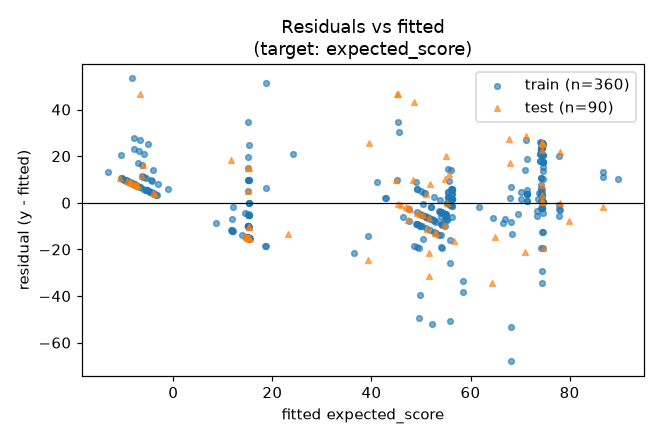

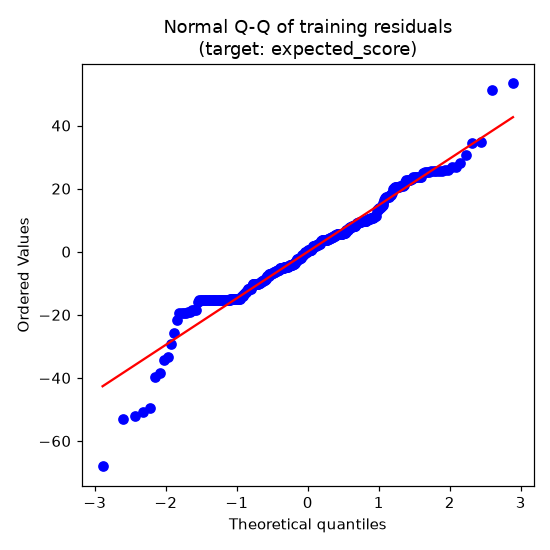

In [2]:
if not status["ready"]:
    print(f"BLOCKED: {status['complete_rows']} of {status['total_rows']} rows have an "
          f"{lr.TARGET_LABEL}; at least {lr.MIN_COMPLETE_ROWS} are needed. No model is fitted.")
    X_all = lr.design_matrix(df)
    print("\nFeature-only facts (no scores involved):")
    print(f"  design matrix for all {X_all.shape[0]} pairs: {X_all.shape[1]} columns, "
          f"rank {np.linalg.matrix_rank(X_all)}, condition number {np.linalg.cond(X_all):.1f}")
    tr, te = lr.split_by_requirement(df)
    print(f"  requirement split: {tr.requirement_id.nunique()} train / {te.requirement_id.nunique()} test "
          f"requirements ({len(tr)} / {len(te)} pairs)")
else:
    r = lr.run(df)
    print(f"Target: {lr.TARGET_LABEL} (not human-annotated, not ground truth)")
    print("AI judge test-retest consistency:", json.dumps(r["consistency"], indent=2))
    o = r["ols"]
    print(f"cond(X_train) = {o['cond_X']:.2f}, rank {o['rank']} of {o['p']}")
    print(f"max |beta_inverse - beta_lstsq| = {o['max_abs_diff_inverse_vs_lstsq']}")
    print(f"max |beta_sklearn - beta_lstsq| = {o['max_abs_diff_sklearn_vs_lstsq']:.2e}")
    display(pd.DataFrame({"feature": ["intercept"] + lr.FEATURES, "beta_hat": r["beta"]}).round(4))
    display(pd.DataFrame({"train": r["train_metrics"], "test": r["test_metrics"]}).round(4))
    display(pd.Series(r["mle"]).to_frame("value"))
    print("MSE_train == sigma2_MLE:", np.isclose(r["train_metrics"]["MSE"], r["mle"]["sigma2_mle"]))
    import io
    from IPython.display import Image
    f1, f2 = lp.residual_plots(r)
    for fig in (f1, f2):  # the plots module forces the Agg backend, so render PNG bytes
        buf = io.BytesIO(); fig.savefig(buf, format="png", dpi=110); display(Image(buf.getvalue()))

## 10. Diagnostics: do the Gaussian-model assumptions hold?

In [3]:
from scipy import stats
if status["ready"]:
    for name, X, y in [("train", r["X_tr"], r["y_tr"]), ("test", r["X_te"], r["y_te"])]:
        f = X @ r["beta"]
        print(f"{name}: fitted values below 0: {int((f < 0).sum())}, above 100: {int((f > 100).sum())} "
              f"(min {f.min():.2f}, max {f.max():.2f})")
    res = r["y_tr"] - r["X_tr"] @ r["beta"]
    print(f"train residuals: skew {stats.skew(res):.3f}, excess kurtosis {stats.kurtosis(res):.3f}, "
          f"Shapiro-Wilk p = {stats.shapiro(res).pvalue:.2e}")
    sheet = pd.read_csv(lr.SHEET, encoding="utf-8-sig", dtype=str, keep_default_na=False)
    rat = pd.read_csv("data/annotation/ai_scores.csv")
    worst = (r["train"].assign(fitted=r["X_tr"] @ r["beta"], residual=res)
             .merge(sheet[["pair_id", "needed_category", "vendor_title", "vendor_categories"]], on="pair_id")
             .merge(rat[["pair_id", "rationale"]], on="pair_id")
             .nsmallest(5, "residual"))
    display(worst[["pair_id", "needed_category", "vendor_title", "vendor_categories", "category_match",
                   "y", "fitted", "residual", "rationale"]].round(1))

train: fitted values below 0: 61, above 100: 0 (min -13.27, max 89.77)
test: fitted values below 0: 14, above 100: 0 (min -10.71, max 86.83)
train residuals: skew -0.311, excess kurtosis 2.220, Shapiro-Wilk p = 3.59e-08


,pair_id,needed_category,vendor_title,vendor_categories,category_match,y,fitted,residual,rationale
189,P220,fruits,Kingini Handicrafts,fruits;household_homeware;stationery_books,True,0.0,68.1,-68.1,Handicraft shop; fruit listing is noise
122,P153,optical,Hotspot Menswear chengalpattu,apparel_footwear;mobile_accessories;optical,True,15.0,68.1,-53.1,Menswear store; sunglasses at most
234,P295,electronics,Estancia IT Park,electronics,True,0.0,52.2,-52.2,"IT office park, not a shop"
300,P376,pet_supplies,Sri Srinivasa Broilers,pet_supplies,True,5.0,55.8,-50.8,Chicken broiler shop; pet listing is noise
181,P212,fruits,Jockey Exclusive Store,apparel_footwear;fruits,True,0.0,49.6,-49.6,Innerwear store; unrelated


**Reading the diagnostics.**

* The target is bounded (0–100) and clustered near the rubric anchors, so residuals form
  bands, and the linear model predicts some impossible negative scores for far, unrelated
  vendors. A linear mean is a rough approximation for this target.
* The residuals are heavier-tailed than a Gaussian (positive excess kurtosis, Shapiro–Wilk
  rejects normality). Least squares is still the minimum-RSS fit, but the "least squares =
  MLE" interpretation and $\hat\sigma^2$ rest on an assumption that holds only approximately.
* The largest negative residuals are vendors whose **source-file category matches**
  (`category_match = 1`) but which the judge recognised from the title as the wrong kind of
  shop (e.g. a handicraft shop listed under fruits). They show where the noisy category
  labels and the judge disagree, i.e. the judge did not simply copy the feature columns.

## 11. Limitations of this target

* **The target is AI-judged.** $R^2$ measures how well a linear model reproduces the AI
  judge's scores, not true match quality.
* **Same criteria on both sides.** The features capture the same criteria the judge used
  (category, distance vs radius, preference keyword), so a high $R^2$ is expected and is
  **not** proof of a good matcher.
* **Consistency is AI-vs-AI.** The blind check compares two AI judges; there is no human
  inter-rater agreement.
* **Small test set.** Six held-out requirements (90 pairs).